# Exercise 10: Autoencoders 

## About Dataset

The data contains information from the 1990 California census. The data pertains to the houses found in a given California district and some summary stats about them based on the 1990 census data. Be warned the data aren't cleaned so there are some preprocessing steps required! The columns of dataset are as follows:
- longitude
- latitude
- housingmedianage
- total_rooms
- total_bedrooms
- population
- households
- median_income
- medianhousevalue
- ocean_proximity

More information about the feature can be found [here](https://www.linkedin.com/pulse/analyzing-california-housing-prices-dataset-data-science-anand-dubey-jmdhf/)

[California Housing Dataset](https://www.kaggle.com/datasets/vikramtiwari/california-housing-dataset-ml-crash-course) from Kaggle. Dataset can be found also from Moodle.

## Dimensionality Reduction

Dimensionality Reduction is the process of reducing the number of dimensions in the data either by excluding less useful features (Feature Selection) or transform the data into lower dimensions (Feature Extraction). Dimensionality reduction prevents overfitting. Overfitting is a phenomenon in which the model learns too well from the training dataset and fails to generalize well for unseen real-world data.

## Exercise description

Use AutoEncoders for dimensionality reduction i.e. use the bottleneck layer  to reduce the dimensions. This process can be viewed as feature extraction.

### Hints

- The number of neurons in the layers of the encoder will be decreasing, for example 32 -> 7
- The number of neurons in the layers of the decoder will be increasing, for example 7 -> 32 
- The code size/ the number of neurons in bottleneck must be less than the number of features in the data
- Before feeding the data into the AutoEncoder the data must definitely be scaled between 0 and 1 using MinMaxScaler -> Use sigmoid activation function in the output layer which outputs values between 0 and 1.

__This exercises HAVE TO be done in CSC Puhti cloud environment.__

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

I0000 00:00:1795458713.917770 1922455 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795458713.933726 1922455 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795458715.272896 1922455 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795458718.324550 1922455 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

## 2. Load the data

In [2]:
train_df = pd.read_csv('california_housing_train.csv')
test_df = pd.read_csv('california_housing_test.csv')

print('train_df shape:', train_df.shape)
print('test_df shape :', test_df.shape)
train_df.head()

train_df shape: (17000, 9)
test_df shape : (3000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


## 3. Inspect the data (dtypes, missing values, basic stats)

In [3]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


In [4]:
print('Missing values (train):')
print(train_df.isna().sum())
print('\nMissing values (test):')
print(test_df.isna().sum())

Missing values (train):
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

Missing values (test):
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64


In [5]:
train_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 4. Preprocessing

Every column is numeric and there are no missing values (confirmed above), so no imputation or one-hot encoding is needed.  

The only required step per the assignment hints is scaling every feature to `[0, 1]` with
`MinMaxScaler`, since the autoencoder's output layer uses `sigmoid`.

## 5. Separate features/target and scale

We keep `median_house_value` out of the autoencoder input — the exercise is about reducing the
dimensionality of the *features*, not reconstructing the target. We use the provided train/test
files directly instead of making our own split.

Important: the scaler is **fit only on the train set**, then just applied (`transform`, not
`fit_transform`) to the test set.

In [6]:
feature_cols = [c for c in train_df.columns if c != 'median_house_value']

X_train = train_df[feature_cols].values
X_test = test_df[feature_cols].values

y_train = train_df['median_house_value'].values
y_test = test_df['median_house_value'].values

print('Number of input features:', X_train.shape[1])

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape:', X_train_scaled.shape)
print('Test shape :', X_test_scaled.shape)
print('Train min/max after scaling:', X_train_scaled.min(), X_train_scaled.max())
print('Test min/max after scaling (can be slightly outside [0,1], that is expected):',
      X_test_scaled.min(), X_test_scaled.max())

Number of input features: 8
Train shape: (17000, 8)
Test shape : (3000, 8)
Train min/max after scaling: 0.0 1.0
Test min/max after scaling (can be slightly outside [0,1], that is expected): 0.0 1.0


## 6. Build the Autoencoder

Following the hints:
- Encoder: decreasing layer sizes, e.g. `n_features -> 32 -> 16 -> 7` (bottleneck)
- Decoder: increasing layer sizes, mirrored: `7 -> 16 -> 32 -> n_features`
- Bottleneck size (7) is smaller than the number of input features, so this is genuine dimensionality reduction.
- Output layer uses `sigmoid`, matching the `[0, 1]` scaled input, and the model is trained to reconstruct its own input (`X -> X`).

In [7]:
n_features = X_train_scaled.shape[1]
bottleneck_dim = 7  # must be < n_features

assert bottleneck_dim < n_features, 'Bottleneck must be smaller than the number of input features'

input_layer = keras.Input(shape=(n_features,))

# Encoder: decreasing
x = layers.Dense(32, activation='relu')(input_layer)
x = layers.Dense(16, activation='relu')(x)
bottleneck = layers.Dense(bottleneck_dim, activation='linear', name='bottleneck')(x)

# Decoder: increasing (mirrored)
x = layers.Dense(16, activation='relu')(bottleneck)
x = layers.Dense(32, activation='relu')(x)
output_layer = layers.Dense(n_features, activation='sigmoid')(x)

autoencoder = keras.Model(inputs=input_layer, outputs=output_layer, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

E0000 00:00:1795458719.390217 1922455 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 7)              │           119 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,871 (7.31 KB)

 Trainable params: 1,871 (7.31 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the Autoencoder

In [8]:
history = autoencoder.fit(
    X_train_scaled, X_train_scaled,
    validation_data=(X_test_scaled, X_test_scaled),
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=1,
)

Epoch 1/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 627us/step - loss: 0.0184 - val_loss: 0.0030
Epoch 2/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0014 - val_loss: 7.4145e-04
Epoch 3/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step - loss: 6.2844e-04 - val_loss: 6.1844e-04
Epoch 4/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 5.2635e-04 - val_loss: 5.3748e-04
Epoch 5/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 469us/step - loss: 4.6373e-04 - val_loss: 4.6200e-04
Epoch 6/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step - loss: 3.9764e-04 - val_loss: 3.6062e-04
Epoch 7/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - loss: 2.9143e-04 - val_loss: 2.3901e-04
Epoch 8/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 2.0207e-04 - val_loss: 1.8308e-04
Epoch 9/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 1.7025e-04 - val_loss: 1.6158e-04
Epoch 10/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 476us/step - loss: 1.5289e-04 - val_loss: 1.4727e-04
Epoch 11/100
532/532 ━━━━━━━━━━━━━━━━━━━━

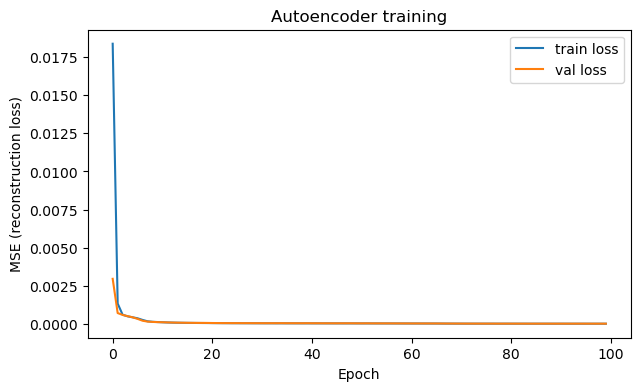

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('MSE (reconstruction loss)')
plt.title('Autoencoder training')
plt.legend()
plt.show()

## 8. Extract the reduced-dimension features (encoder output)

A separate `encoder` model that stops at the bottleneck layer, so we can transform any row into its 7-number compressed representation.

In [10]:
encoder = keras.Model(inputs=input_layer, outputs=bottleneck, name='encoder')

X_train_encoded = encoder.predict(X_train_scaled)
X_test_encoded = encoder.predict(X_test_scaled)

print('Original feature count :', X_train_scaled.shape[1])
print('Reduced feature count  :', X_train_encoded.shape[1])

pd.DataFrame(X_train_encoded, columns=[f'latent_{i}' for i in range(bottleneck_dim)]).head()

532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 226us/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 280us/step
Original feature count : 8
Reduced feature count  : 7


,latent_0,latent_1,latent_2,latent_3,latent_4,latent_5,latent_6
0,0.212130,-2.099211,1.734842,-2.866962,1.751511,0.385143,1.209123
1,0.234517,-2.242800,1.645850,-2.619905,1.661929,0.419168,1.110997
2,-0.035212,-2.196058,1.569080,-3.817576,1.720569,-0.066760,1.173094
3,0.232159,-2.141718,1.390686,-3.307064,1.497432,-0.082463,1.289244
4,0.150701,-2.236670,1.525074,-3.459357,1.731717,-0.002416,1.018670


In [ ]:
# Check for near-zero variance in the latent features
latent_std = X_train_encoded.std(axis=0)
for i, s in enumerate(latent_std):
    flag = '  <-- near-zero variance, likely dead' if s < 1e-4 else ''
    print(f'latent_{i}: std = {s:.6f}{flag}')

latent_0: std = 0.482558
latent_1: std = 0.495475
latent_2: std = 0.570137
latent_3: std = 0.448679
latent_4: std = 0.415417
latent_5: std = 0.415734
latent_6: std = 0.463287


## 9. Sanity check: does the reduced representation preserve useful structure?

A quick, simple check: correlate each of the 7 latent features with `median_house_value` (which we held out of the autoencoder entirely). If the autoencoder learned something meaningful, at least some latent dimensions should correlate with the target, even though it never saw it during training.

In [12]:
# y_train / y_test (median_house_value) were already set aside in Step 5,
# and were never shown to the autoencoder during training.
latent_df = pd.DataFrame(X_train_encoded, columns=[f'latent_{i}' for i in range(bottleneck_dim)])
latent_df['median_house_value'] = y_train

latent_df.corr()['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
latent_0              0.233424
latent_3              0.197761
latent_6             -0.073558
latent_1             -0.117239
latent_2             -0.244072
latent_4             -0.261855
latent_5             -0.360072
Name: median_house_value, dtype: float64

# Conclusion

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing this__

Write conclusion:

## Results

An autoencoder was built to compress the 8 numeric features of the California housing dataset
(`longitude`, `latitude`, `housing_median_age`, `total_rooms`, `total_bedrooms`, `population`,
`households`, `median_income`) down to a 7-number bottleneck representation, following the
architecture `8 -> 32 -> 16 -> 7 (bottleneck) -> 16 -> 32 -> 8`. `median_house_value` was held out
of the input entirely and used only afterwards, to check whether the compressed representation
still carried useful signal.

Trained for 100 epochs, the final model reached a reconstruction loss (MSE) of **~4.35e-05** on
the training set and **~4.66e-05** on the held-out test set — train and validation loss tracked
closely throughout training, with no sign of overfitting.

Checking the standard deviation of each of the 7 bottleneck dimensions confirmed all of them were
actively used (std roughly 0.42-0.57 across the board, no dimension stuck at zero). Correlating
each bottleneck dimension against the held-out `median_house_value` showed every dimension picked
up some relationship with price (correlations roughly -0.36 to +0.23), with the signal spread
fairly evenly across all 7 dimensions rather than concentrated in one or two. This is evidence the
autoencoder learned a genuinely compressed, non-trivial representation of the original 8
features — not just a copy of a subset of them.

## Development process

The first working version of the model used `relu` activation on the bottleneck layer, in line
with the rest of the encoder. That version trained without errors and produced a higher
reconstruction loss (~2.9e-04 train / ~3.1e-04 test). Inspecting the 7 extracted bottleneck
features afterwards, however, showed that 2 of the 7 dimensions were exactly 0.0 for every single
row, and a third had negligible variance (correlation with `median_house_value` of ~0.00001) —
only about 4 of the 7 allotted dimensions were actually doing any work.

This is the well-known "dying ReLU" problem: ReLU clips any negative pre-activation to exactly 0,
and since its gradient is also 0 in that region, a neuron that lands there during training has no
way to recover. The fix applied was to change only the bottleneck layer's activation from `relu`
to `linear` (no activation), while leaving the surrounding hidden layers on `relu` and the output
layer on `sigmoid` (as required by the exercise, since the data is scaled to `[0, 1]`). A linear
bottleneck does not clip negative values, so every dimension is free to carry information in both
directions.

Re-training with this one change fixed the dead-neuron problem completely (all 7 dimensions showed
healthy variance) and also reduced reconstruction loss by roughly 6-7x compared to the `relu`
bottleneck version, confirming that the earlier dead neurons were genuinely wasting bottleneck
capacity rather than the model simply not needing all 7 dimensions.

## Takeaway

The exercise's hints (decreasing encoder, increasing decoder, bottleneck smaller than the input,
`[0, 1]` scaling with a sigmoid output) were sufficient to build a working autoencoder, but getting
a bottleneck that actually uses its full allotted dimensionality required one additional, less
obvious choice: using an activation on the bottleneck itself that does not clip values to zero.
This is also the standard textbook choice for an autoencoder bottleneck — with a fully linear
network, an autoencoder reduces to something close to PCA, so a linear bottleneck is a
well-grounded default rather than an unusual workaround.

## AI Usage
I used AI as an assistant in this exercise. It helped me check my code against the exercise, remove unused code and understand the results and document the conclusion in an organised way.